# E51: Do weight statistics of a fine-tune tell eliciting from teaching?

## The answer

Mostly no. We looked only at the weight change of eight small fine-tunes. Four taught the model to repeat a word, which it already could; four taught an arbitrary word mapping it lacked. Where the change sits relative to the original model's main directions does not tell the two kinds apart, and no fine-tune created a new main direction. The spread of the change across directions differs by just enough to pass our rule, but it tracks how large the change is, and the mapping fine-tunes were larger.


## What we were trying to test

The project's claim is that a VPD decomposition can tell whether a fine-tune teaches something new or brings out something the model already had. A reviewer will ask whether a cheaper method, looking only at the weights, would have said the same. This notebook runs the cheapest such method.

The updates are the eight fine-tunes of the 67M model from E12, regenerated in E46. Each trains all 24 decomposed matrices with Adam on key-to-value windows. Four are *copy* tasks, where the value repeats the key: the model can already do this, so these updates elicit. Four are *cipher* tasks, where each of 32 keys maps to an arbitrary word: the original model gives the target about one in a million, so these updates teach. Each kind has two tables of keys, A and B, and two training seeds. A ninth update, a fine-tune on code text that learned nothing, is shown for reference. It is the case where VPD's reading fails, since Γ's new values carry most of its tiny change.

For each matrix, with $\delta W$ the weight change and $W_0$ the original weights, we measure three things from the literature:

- **Top-10 share**: the fraction of $\delta W$'s squared size that lies along $W_0$'s ten largest singular directions, averaged over the output and input sides. It reads 1 when the update only re-weights the original's main directions, and about 0.01 for a random update.
- **Intruder dimensions**, from Shuttleworth and colleagues in 2024: how many of the ten largest singular directions of $W_0 + \delta W$ have cosine below 0.5 with every singular direction of $W_0$. Ten and 0.5 are the paper's settings. It reads 0 when the update creates no new main direction.
- **Effective rank** of $\delta W$, from Roy and Vetterli in 2007: the exponential of the entropy of its normalised singular values. It reads 1 for a rank-one change and about 700 for a random one.

Each number is averaged over the 24 matrices, weighting each matrix by $\|\delta W\|^2$. Every update is compared with a random Gaussian update of the same size in every matrix. Two synthetic updates check the apparatus before any real one is read. A pure re-weighting of $W_0$'s top ten directions must read share 1, no intruders and rank 10. A single new direction twice as strong as $W_0$'s largest must read one intruder per matrix and rank 1.


## What we expected, and why

A statistic counts as separating the kinds when the gap between the copy and cipher means is larger than the spread of values within either kind. We expected no separation for the top-10 share or for the effective rank, with medium confidence. E12 found that the share of the update outside the decomposition's subcomponents was the same for both kinds, and these are cruder versions of that number. For intruder dimensions we had no expectation.


## What we observed

### Do the three statistics tell copy from cipher, as VPD's reading does?


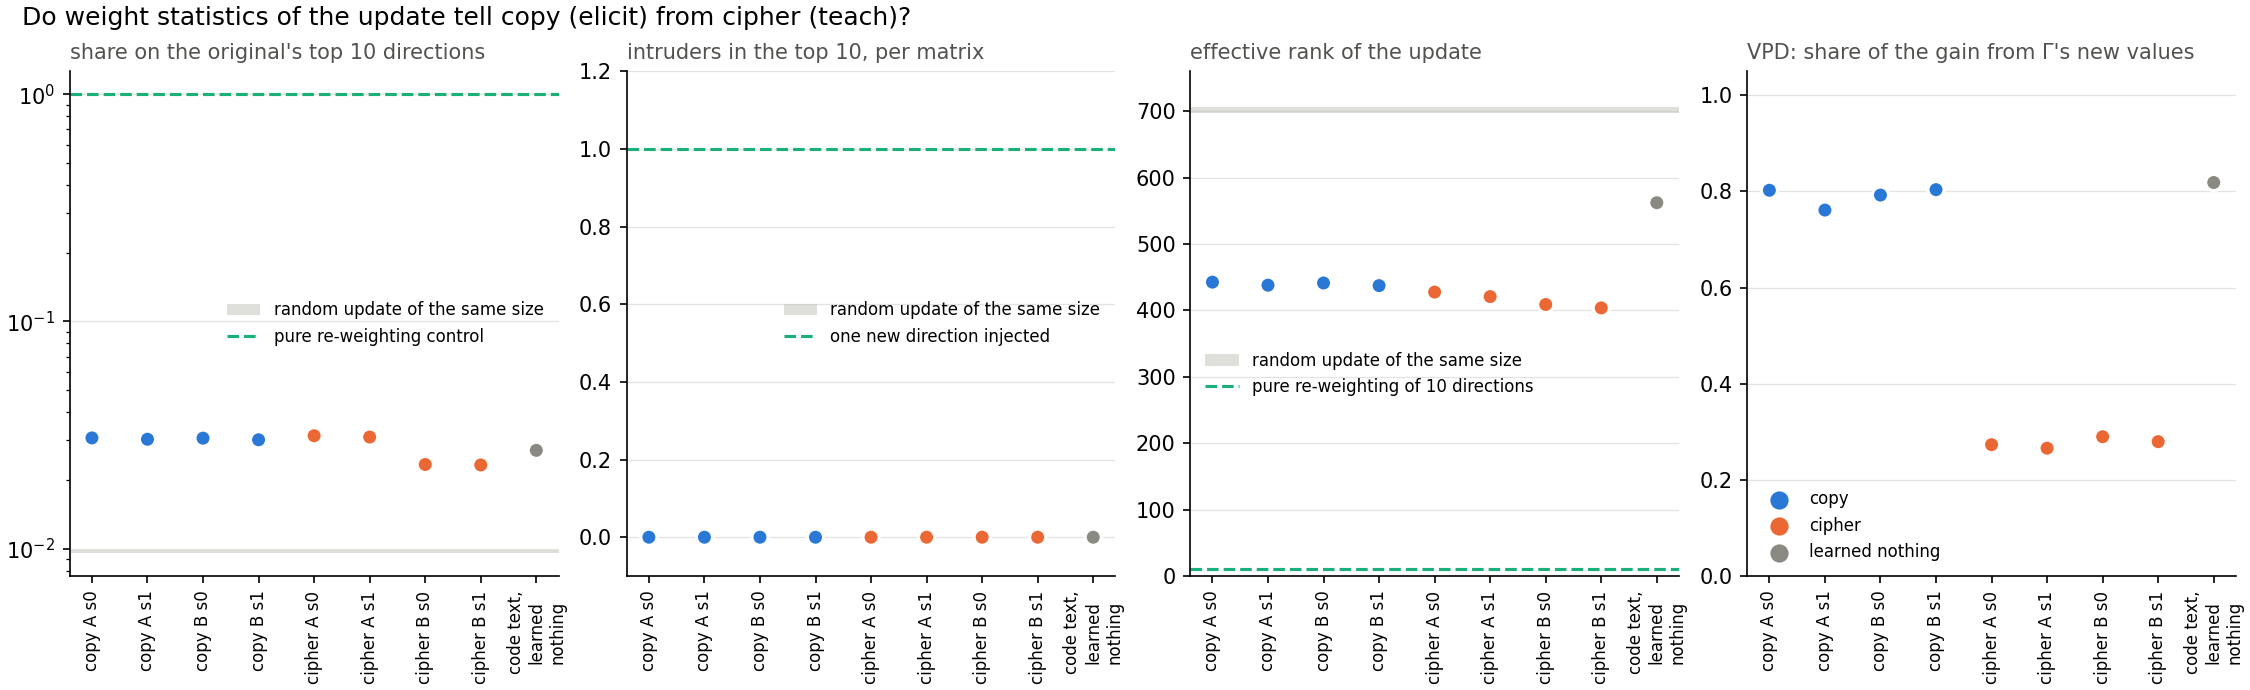

In [1]:
from pathlib import Path
from IPython.display import Image, display
FIG = Path("../experiments/baseline_weights/figures")
display(Image(filename=str(FIG / "weights.png")))


**Reading it.** Only the effective rank passes the rule, and only just; VPD's reading, in the right-hand panel, separates the kinds by a wide margin. Every fine-tune puts about three times the random share on $W_0$'s top directions, 0.03 against 0.01. But copy and cipher overlap: cipher table B sits below every copy update, cipher table A above. No update creates an intruder, while the injected direction reads exactly one per matrix, so the count could have moved and did not. The effective rank is about 440 for the copy updates and between 400 and 430 for the cipher updates, far below the random update's 700. The gap between the kind means, 24.5, beats the within-kind spread, 23.9, by three percent.


### Does the effective rank follow the kind of update, or its size?


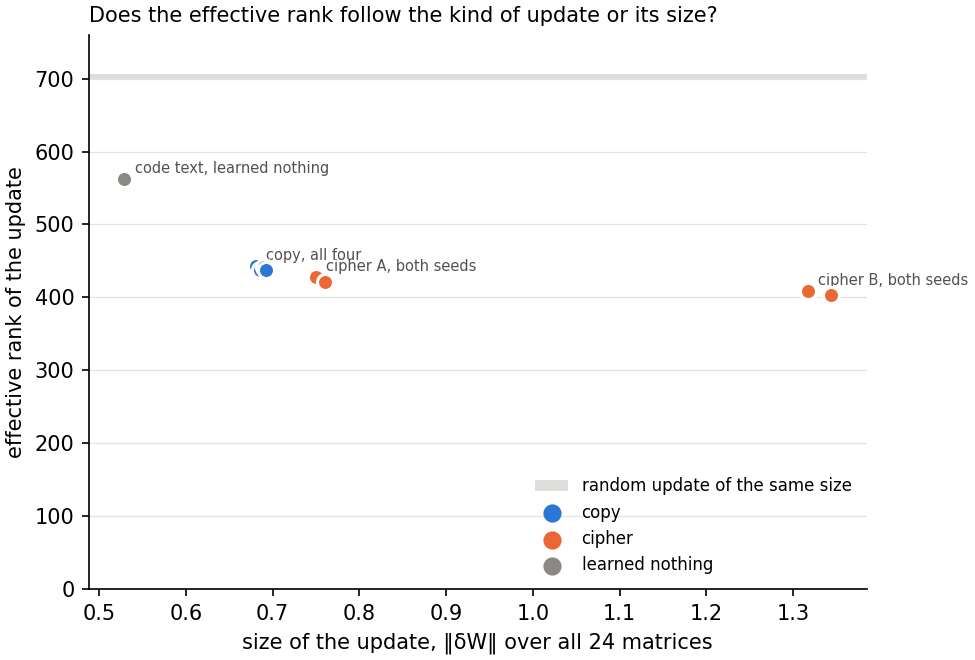

In [2]:
display(Image(filename=str(FIG / "erank_vs_size.png")))


**Reading it.** The effective rank falls as the update grows, across all nine updates, so its separation cannot be credited to the kind. Each cipher update is larger than every copy update: table A by about a tenth, and table B, trained for 30 steps rather than 10, nearly twice as large. The code fine-tune that learned nothing is the smallest update and has the highest rank, about 560. Among the four copy updates, whose sizes are almost equal, the rank barely moves. This set has no copy and cipher pair of equal size, so it cannot tell the two causes apart.


In [3]:
import json
R = json.loads(Path("../experiments/baseline_weights/results/results.json").read_text())
print(f"{'update':14s} {'kind':16s} {'size':>5s} {'top-10 share':>12s} {'intruders':>9s} {'eff. rank':>9s}")
for n, r in R["states"].items():
    size = sum(v["norm2"] for v in r["per_matrix"].values()) ** 0.5
    a = r["agg"]
    print(f"{n:14s} {r['kind']:16s} {size:5.2f} {a['share']:12.4f} {a['intruders']:9.1f} {a['erank']:9.0f}")


update         kind              size top-10 share intruders eff. rank
ident32_s0     copy              0.68       0.0307       0.0       442
ident32_s1     copy              0.69       0.0303       0.0       438
ident32b_s0    copy              0.69       0.0307       0.0       441
ident32b_s1    copy              0.69       0.0302       0.0       437
rand32_s0      cipher            0.75       0.0314       0.0       428
rand32_s1      cipher            0.76       0.0310       0.0       421
rand32b_s0     cipher            1.32       0.0235       0.0       409
rand32b_s1     cipher            1.34       0.0234       0.0       404
code_step10    learned nothing   0.53       0.0271       0.0       562


## What we learned

Weight statistics of the update alone do not reproduce VPD's verdict on these fine-tunes. Two of the three see no difference between eliciting and teaching. The third differs by a hair and in step with the update's size. This answers the weight-only objection for the 67M copy and cipher set: VPD's reading of which subcomponents Γ switches on is not something a spectrum of $\delta W$ already shows. It does not answer the stronger objections, from neurons, activations and behaviour, which act on the model rather than its weights.

## How compelling is the evidence

The statistics are exact on fixed weights, so there is no sampling noise; the only spread is between seeds and tables. Eight updates in two kinds, on one model and one task format, is a small set. The controls show that each statistic can move: re-weighting reads share 1 and rank 10, the injected direction reads one intruder. The intruder count is close to blind at this size. Each matrix changed by under three percent of its size, and no change was stronger than a twelfth of $W_0$'s top singular value, too weak to displace a top direction. The update sizes are confounded with kind, so a rank difference is uninterpretable here. All three statistics are blind to which inputs the update acts on.

## Surprises

The effective rank passed the separation rule against its filed lean of no separation, by three percent of the spread. We report it as a narrow pass and do not credit it to the kind, because it follows update size. Every real update, even the one that learned nothing, put three times the random share on $W_0$'s top directions. That looks like a property of Adam's first steps on this model, not of the task.

## What next

- A size-matched pair: a cipher checkpoint at the copy updates' size, or effective rank compared at equal $\|\delta W\|$. If the rank gap survives, it is a weight-space signal worth adding to the comparison table; if not, B1 is closed.
- The neuron, steering and behavioural baselines of the scoping plan, which are the objections that matter, on the same eight updates plus the code fine-tune.


## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| C | controls read their filed values | re-weighting share ≥ 0.999, 0 intruders, rank 10 ± 0.01; injected 1 ± 0.05 intruders, rank 1 ± 0.01; null share within 10% of random, 0 intruders | 1.000, 0, 10.00; 1.00, 1.00; 0.0097 vs 0.0097, 0 | pass |
| P1 | top-10 share separates | gap of kind means > larger within-kind range | gap 0.0031, range 0.0081 | does not separate, as leaned |
| P2 | intruder count separates | same | gap 0, range 0 | does not separate, no lean |
| P3 | effective rank separates | same | gap 24.5, range 23.9 | separates, against the lean; follows size |

## Not run

Size-matched updates; per-layer breakdown; the LoRA amplification factor listed in the plan's table, which needs a low-rank update; intruders at other $k$ or thresholds; the neuron, steering, behavioural, dictionary and probe baselines.

Provenance: `experiments/baseline_weights/run.py`, results `experiments/baseline_weights/results/results.json`, filed rules `results/predictions.json`. Cluster CPU worker through `fleet/cpu-run`, 2 CPUs, about 7 minutes, $0. Updates from `~/commute-data/results-large/regating_table/`; $W_0$ read as tensors from the target checkpoint. Report: `reports/analyses/2026-10-29_analysis_baseline-weights.md`.
